## Alumno: Gloria de las Nieves Sánchez Ramírez

Vídeo Youtube: https://youtu.be/PWK5WkD6ZJQ

# Proyecto completo de Machine Learning
## ¿Cómo influyen los hábitos de estudio y el uso de la IA en la nota final de un estudiante?




### Resumen del proyecto (en pocas palabras)

* **Datos:** 50.000 estudiantes universitarios con información de sus notas, sus horas de estudio y cómo usan la IA.
* **Objetivo:** predecir la **nota final del semestre** (`nota_final`) de cada estudiante.
* **Resultado:** el mejor modelo (**Random Forest ajustado**) tiene un error típico (RMSE) de unos **0.15 puntos** de nota (escala 0-4). Si solo usáramos la nota previa el error sería **0.18**, y si predijéramos siempre la media sería **0.49**.
* **Idea principal:** la nota previa explica la mayor parte de la nota final, pero los hábitos (horas de estudio, cuántas horas de IA y para qué se usa) mejoran la predicción. Usar la IA de forma moderada y para depurar errores se relaciona con una mayor mejora de nota; usarla muchísimo o para pedir respuestas directas, con una mejora menor.


In [ ]:
# Librerías que vamos a usar
import numpy as np                 # cálculos numéricos
import pandas as pd                # tablas de datos (DataFrame)
import matplotlib.pyplot as plt    # gráficas
import seaborn as sns              # gráficas más bonitas


## 1. Obtención de datos

* **Fuente:** Kaggle, dataset *AI Student Impact* (archivo `ai_student_impact_dataset (1).csv`).
* **Contenido:** 50.000 estudiantes universitarios con datos académicos y de uso de IA generativa.
* **Cómo se obtuvieron:** Se han obtenido en Kaggle, a partir de encuestas académicas a estudiantes universitarios combinadas con los registros de calificaciones y pruebas de retención de las instituciones educativas.
* **Aviso importante:** los datos están *demasiado* limpios (sin nulos, sin duplicados, valores siempre dentro de rango), así que **probablemente son datos simulados (sintéticos)**. Por eso las conclusiones valen para *estos datos*, y no se pueden generalizar sin más a estudiantes reales.

Cargamos el CSV en un `DataFrame` de pandas, que es la estructura que nos permite manipular los datos y entrenar modelos.

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv("/content/drive/MyDrive/ai_student_impact_dataset (1).csv")

estudiantes.head()

Mounted at /content/drive


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium



## 2. Los datos

El dataset original tiene los nombres de las columnas en inglés. Para entenderlos y explicarlos mejor, **los traducimos al español** (y también los valores de texto). Esta es la equivalencia y el significado de cada atributo:

In [ ]:
# Traducimos los nombres de las columnas
nombres = {
    "Student_ID": "id_estudiante",
    "Major_Category": "rama_estudios",
    "Year_of_Study": "curso",
    "Pre_Semester_GPA": "nota_previa",
    "Weekly_GenAI_Hours": "horas_ia",
    "Primary_Use_Case": "uso_principal_ia",
    "Prompt_Engineering_Skill": "nivel_prompts",
    "Tool_Diversity": "num_herramientas_ia",
    "Paid_Subscription": "suscripcion_pago",
    "Traditional_Study_Hours": "horas_estudio_tradicional",
    "Perceived_AI_Dependency": "dependencia_ia",
    "Institutional_Policy": "politica_universidad",
    "Anxiety_Level_During_Exams": "ansiedad_examenes",
    "Post_Semester_GPA": "nota_final",
    "Skill_Retention_Score": "retencion_conocimientos",
    "Burnout_Risk_Level": "riesgo_agotamiento",
}
estudiantes = estudiantes.rename(columns=nombres)

# Traducimos también los valores de texto
traducciones = {
    "rama_estudios": {"STEM": "STEM", "Business": "Empresa", "Humanities": "Humanidades", "Medical": "Salud", "Arts": "Artes"},
    "curso": {"Freshman": "1º curso", "Sophomore": "2º curso", "Junior": "3º curso", "Senior": "4º curso", "Graduate": "Posgrado"},
    "uso_principal_ia": {"Debugging/Troubleshooting": "Depurar errores", "Copywriting/Drafting": "Redactar textos", "Ideation": "Generar ideas", "Summarizing_Reading": "Resumir lecturas", "Direct_Answer_Generation": "Respuestas directas"},
    "nivel_prompts": {"Beginner": "Principiante", "Intermediate": "Intermedio", "Advanced": "Avanzado"},
    "politica_universidad": {"Allowed_With_Citation": "Permitida con cita", "Actively_Encouraged": "Fomentada", "Strict_Ban": "Prohibida"},
    "riesgo_agotamiento": {"Low": "Bajo", "Medium": "Medio", "High": "Alto"},
}

for columna, diccionario in traducciones.items():
    estudiantes[columna] = estudiantes[columna].map(diccionario)

# Orden natural de las categorías que tienen orden (lo usaremos en gráficas y en el modelo)
ORDENES = {
    "curso": ["1º curso", "2º curso", "3º curso", "4º curso", "Posgrado"],
    "nivel_prompts": ["Principiante", "Intermedio", "Avanzado"],
    "riesgo_agotamiento": ["Bajo", "Medio", "Alto"],
}
estudiantes.head()

,id_estudiante,rama_estudios,curso,nota_previa,horas_ia,uso_principal_ia,nivel_prompts,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,politica_universidad,ansiedad_examenes,nota_final,retencion_conocimientos,riesgo_agotamiento
0,100001,Humanidades,4º curso,2.418,23.31,Redactar textos,Principiante,1,True,8.13,5,Permitida con cita,6,2.393,86.44,Alto
1,100002,Salud,3º curso,3.821,1.12,Generar ideas,Avanzado,5,False,16.65,3,Permitida con cita,9,3.696,69.39,Bajo
2,100003,Empresa,1º curso,3.398,21.26,Resumir lecturas,Principiante,2,False,10.35,5,Prohibida,9,3.499,73.93,Medio
3,100004,Empresa,4º curso,3.789,1.82,Redactar textos,Intermedio,4,False,15.23,2,Permitida con cita,2,4.000,63.58,Medio
4,100005,STEM,2º curso,3.635,9.29,Depurar errores,Avanzado,4,False,12.55,4,Permitida con cita,4,3.798,100.00,Medio


In [ ]:
# Resumen técnico: nº de filas, tipo de cada columna y valores no vacíos
estudiantes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_estudiante              50000 non-null  int64  
 1   rama_estudios              50000 non-null  object 
 2   curso                      50000 non-null  object 
 3   nota_previa                50000 non-null  float64
 4   horas_ia                   50000 non-null  float64
 5   uso_principal_ia           50000 non-null  object 
 6   nivel_prompts              50000 non-null  object 
 7   num_herramientas_ia        50000 non-null  int64  
 8   suscripcion_pago           50000 non-null  bool   
 9   horas_estudio_tradicional  50000 non-null  float64
 10  dependencia_ia             50000 non-null  int64  
 11  politica_universidad       50000 non-null  object 
 12  ansiedad_examenes          50000 non-null  int64  
 13  nota_final                 50000 non-null  flo

**Qué vemos:** hay **50.000 estudiantes** y **16 columnas**: 6 de texto (categorías), 1 de tipo Sí/No (`suscripcion_pago`) y 9 numéricas (contando `id_estudiante`). Todas las columnas están completas.

In [ ]:
# Estadísticas de las columnas numéricas: media, desviación, mínimo, cuartiles y máximo
estudiantes.describe().round(2)

,id_estudiante,nota_previa,horas_ia,num_herramientas_ia,horas_estudio_tradicional,dependencia_ia,ansiedad_examenes,nota_final,retencion_conocimientos
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,125000.50,3.15,8.43,2.80,11.21,3.51,4.27,3.35,75.80
std,14433.90,0.48,8.27,1.19,5.16,1.82,2.14,0.50,13.28
min,100001.00,1.18,0.00,1.00,1.00,1.00,1.00,1.00,10.78
25%,112500.75,2.83,2.39,2.00,7.56,2.00,3.00,3.02,66.82
50%,125000.50,3.21,5.80,3.00,11.18,3.00,4.00,3.42,76.00
75%,137500.25,3.52,11.72,4.00,14.71,5.00,6.00,3.75,85.19
max,150000.00,4.00,40.00,5.00,35.86,10.00,10.00,4.00,100.00


**Qué vemos:**
* La **nota previa** media es 3.15 y la **nota final** media es 3.35: de media los estudiantes suben unas décimas.
* El 25 % de los estudiantes usa la IA menos de 2.4 horas a la semana y el 75 % hasta 11.7 horas (el máximo son 40).
* `nota_final` llega a **4.0** (tope de la escala) y `retencion_conocimientos` a **100** (tope de la prueba).
* Las columnas están en escalas muy distintas (de 1-10 a 0-100): habrá que **escalarlas** antes de entrenar.


## 3. Exploración y visualización de los datos

Antes de entrenar nada, queremos entender los datos: ¿faltan valores?, ¿cómo se reparten?, ¿qué columnas se relacionan con la nota final?

### 3.1 Valores nulos y duplicados

In [ ]:
print("Valores nulos en total:", estudiantes.isnull().sum().sum())
print("Filas duplicadas:", estudiantes.duplicated().sum())
print("¿id_estudiante es único?:", estudiantes["id_estudiante"].is_unique)

Valores nulos en total: 0
Filas duplicadas: 0
¿id_estudiante es único?: True


**Qué vemos:** no hay valores nulos ni filas repetidas, así que **no hace falta limpiar ni rellenar datos**. (Es otra señal de que el dataset probablemente es simulado: en datos reales casi siempre faltan valores).

### 3.2 Variables de texto (categorías)

¿Cuántos estudiantes hay de cada rama de estudios y de cada uso principal de la IA?

In [ ]:
estudiantes["rama_estudios"].value_counts()

,count
rama_estudios,
STEM,15059
Empresa,12538
Humanidades,9994
Salud,6476
Artes,5933


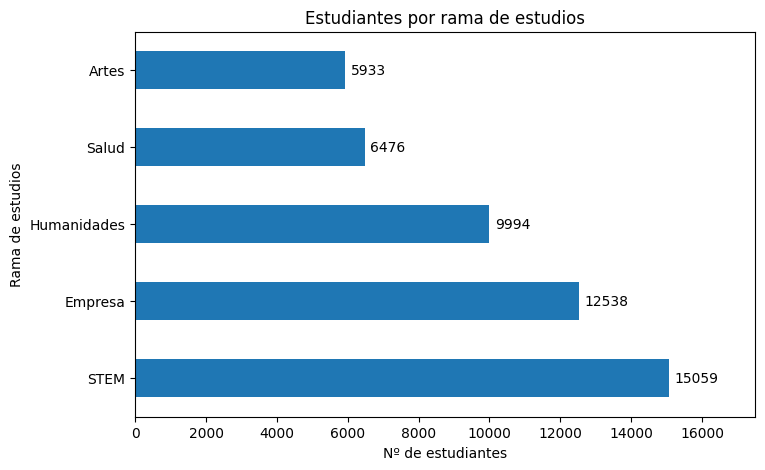

In [ ]:
ax = estudiantes["rama_estudios"].value_counts().plot(kind="barh", figsize=(8, 5))
plt.title("Estudiantes por rama de estudios")
plt.xlabel("Nº de estudiantes")
plt.ylabel("Rama de estudios")
ax.bar_label(ax.containers[0], padding=4)
plt.xlim(0, 17500)
plt.show()

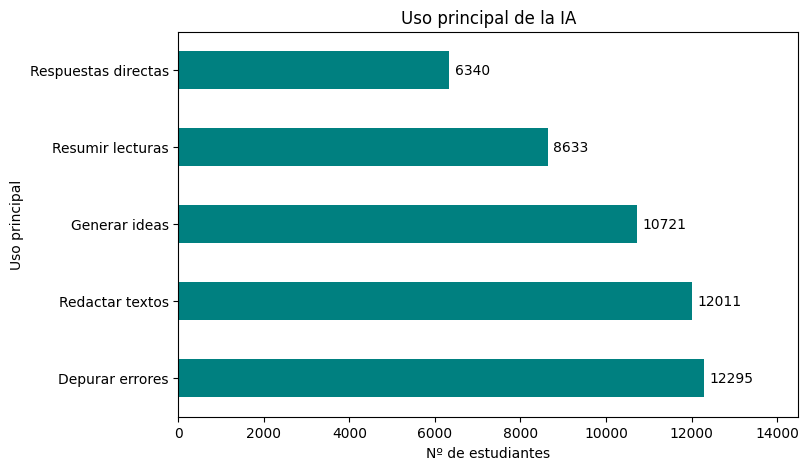

In [ ]:
ax = estudiantes["uso_principal_ia"].value_counts().plot(kind="barh", color="teal", figsize=(8, 5))
plt.title("Uso principal de la IA")
plt.xlabel("Nº de estudiantes")
plt.ylabel("Uso principal")
ax.bar_label(ax.containers[0], padding=4)
plt.xlim(0, 14500)
plt.show()

**Qué vemos:** las categorías están bastante repartidas. La rama más grande es STEM y el uso de la IA menos frecuente es pedir *respuestas directas*. Ninguna categoría tiene tan pocos casos como para dar problemas.

### 3.3 Variables numéricas: histogramas

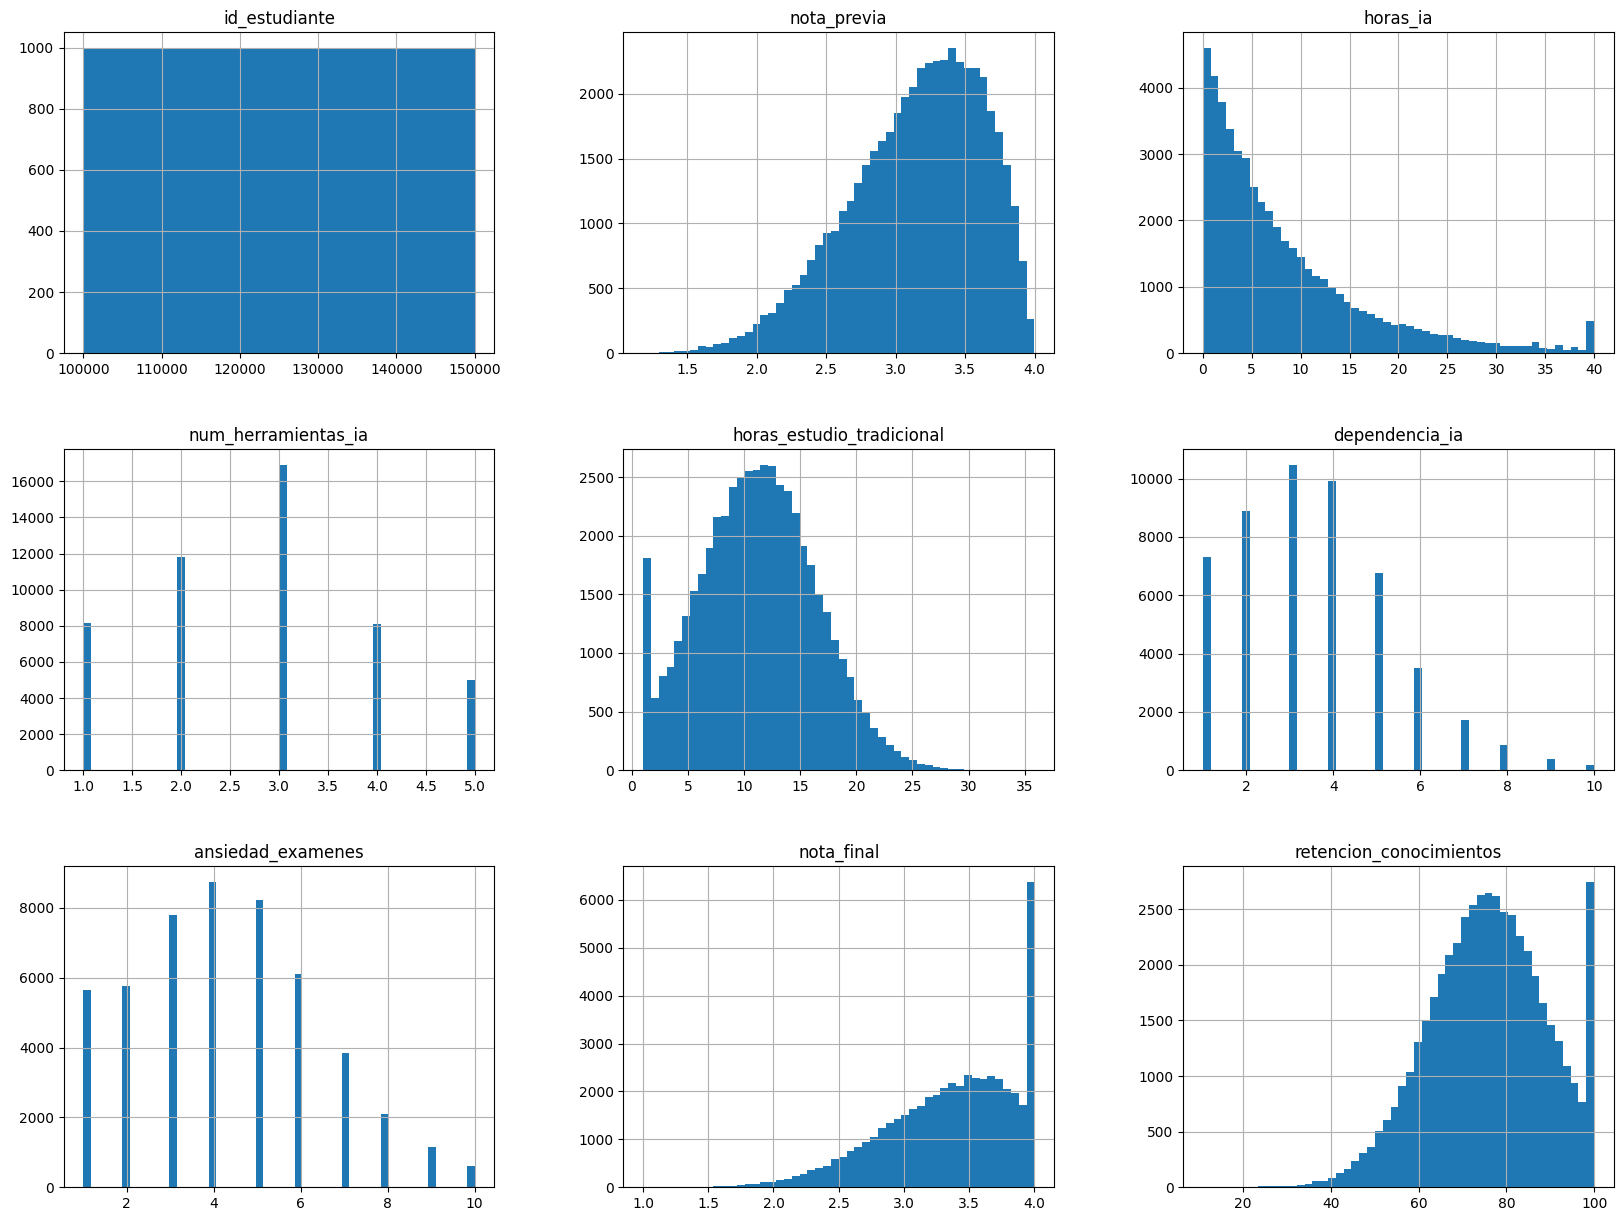

In [ ]:
# Histogramas de todos los datos numéricos
estudiantes.hist(bins=50, figsize=(20, 15))   # bins más grande = barras más finas
plt.show()

**Qué vemos:**
1. `nota_final` y `retencion_conocimientos` tienen un **pico en el máximo** (4.0 y 100): las notas están "cortadas" por arriba. En concreto, el **9.6 %** de los estudiantes tiene exactamente un 4.0.
2. `horas_ia` tiene una **cola larga a la derecha**: la mayoría usa la IA pocas horas, pero algunos llegan a 40.
3. Cada columna tiene una escala distinta (de 1-10 a 0-100).
4. `id_estudiante` es plano (uniforme) porque es solo un número de fila.

### 3.4 Nota previa frente a nota final

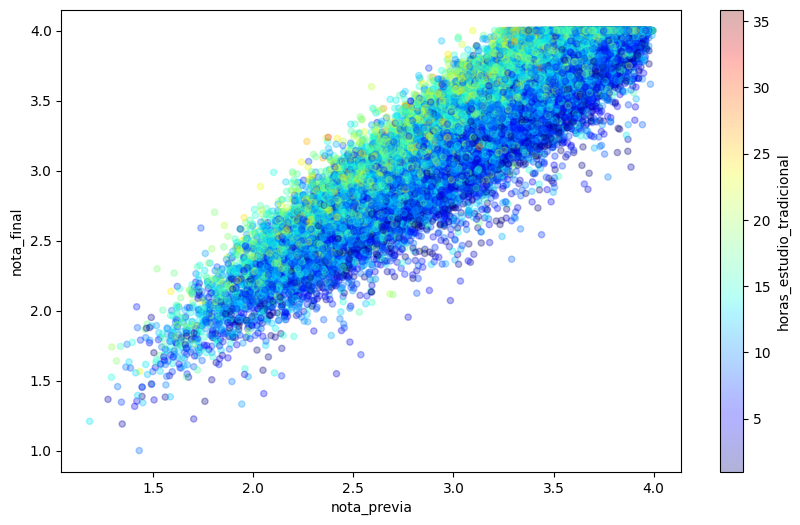

In [ ]:
estudiantes.plot(kind="scatter", x="nota_previa", y="nota_final", alpha=0.3, figsize=(10, 6), c="horas_estudio_tradicional", cmap="jet")   # el color indica las horas de estudio
plt.show()

**Qué vemos:** los puntos siguen una diagonal: la nota final se parece mucho a la previa. Casi todos quedan por encima de la diagonal (la nota sube). Además, los puntos verdes y amarillos (más horas de estudio por su cuenta) tienden a estar más arriba, y los azul oscuro (pocas horas) más abajo. La línea horizontal de arriba del todo es el tope de 4.0.


### 3.5 Correlaciones

In [ ]:
# Matriz de correlaciones (quitamos las columnas de texto y el identificador)
columnas_texto = ["rama_estudios", "curso", "uso_principal_ia", "nivel_prompts", "politica_universidad", "riesgo_agotamiento"]
estudiantes_numerico = estudiantes.drop(columnas_texto + ["id_estudiante"], axis=1)
corr_matrix = estudiantes_numerico.corr()

In [ ]:
# Relación de cada uno de los atributos con la nota final
# (cerca de 1: suben juntas; cerca de -1: una sube y la otra baja; cerca de 0: no se relacionan)
corr_matrix["nota_final"].sort_values(ascending=False)

,nota_final
nota_final,1.000000
nota_previa,0.926781
retencion_conocimientos,0.169616
horas_estudio_tradicional,0.137653
num_herramientas_ia,0.025265
suscripcion_pago,0.005528
dependencia_ia,-0.014180
ansiedad_examenes,-0.015909
horas_ia,-0.018600


Vemos que hay una correlación **muy fuerte** entre `nota_final` y `nota_previa` (**0.93**), seguida de `retencion_conocimientos` (0.17) y `horas_estudio_tradicional` (0.14). `horas_ia` casi no tiene correlación lineal con la nota final (-0.02), pero sí con `dependencia_ia` (0.67): quien usa más la IA se siente más dependiente.

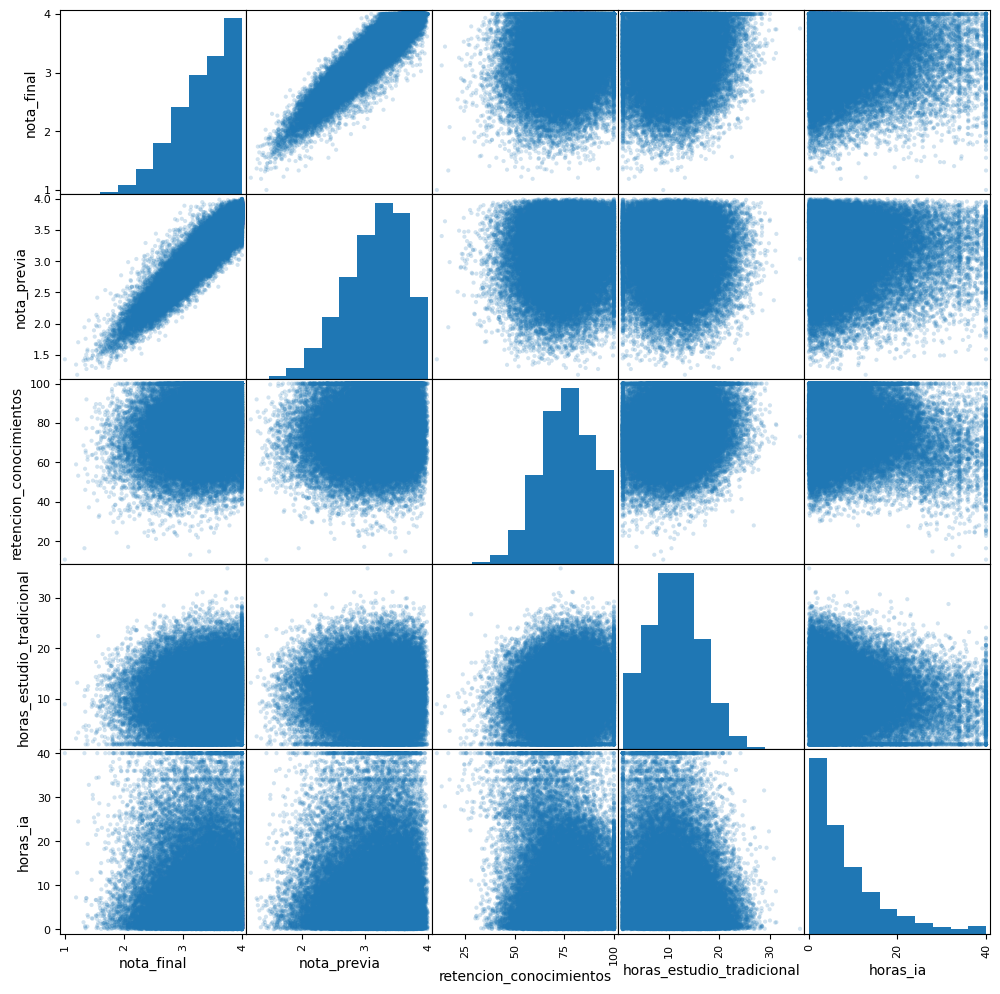

In [ ]:
from pandas.plotting import scatter_matrix

atributos = ["nota_final", "nota_previa", "retencion_conocimientos", "horas_estudio_tradicional", "horas_ia"]
scatter_matrix(estudiantes[atributos], figsize=(12, 12), alpha=0.2)
plt.show()

En las diagonales, en lugar de salir una línea recta que no serviría de nada, sale el histograma de cada atributo. Se ve claramente la relación entre `nota_previa` y `nota_final`, y que `horas_ia` no sigue ninguna recta con la nota.

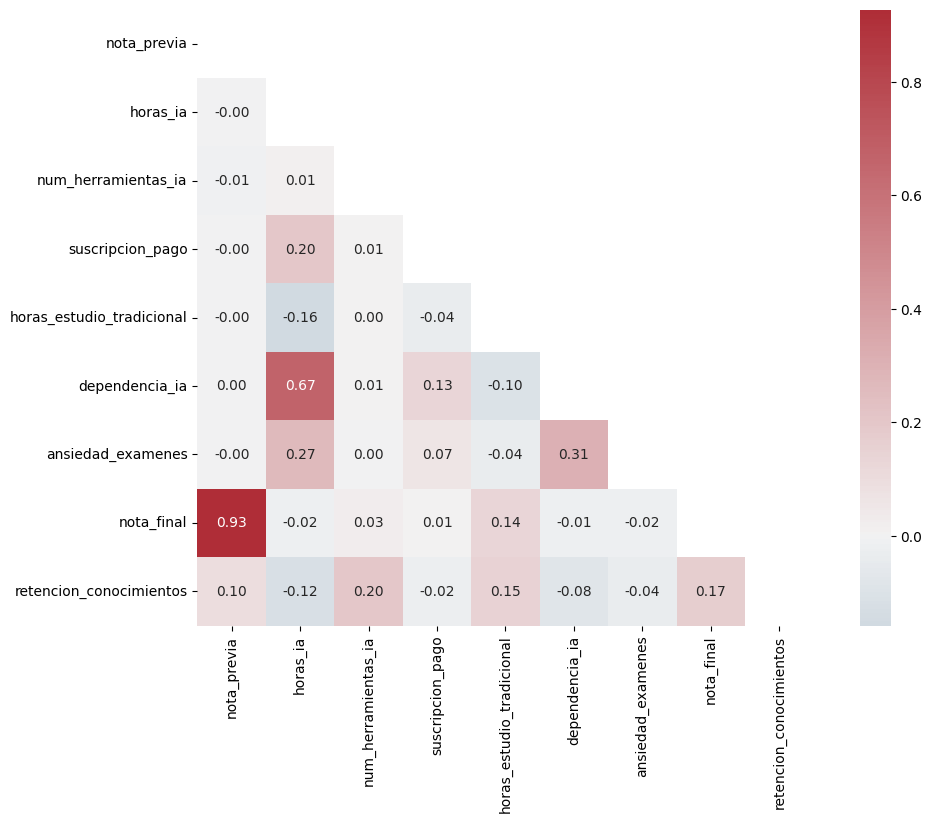

In [ ]:
# Mapa de calor de las correlaciones, mostrando solo la mitad de abajo (la de arriba es igual)

# Máscara que oculta la parte de arriba de la matriz
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Paleta de colores: azul-rojo con el blanco en el centro (en el 0)
cmap = sns.diverging_palette(240, 10, s=75, l=40, n=5, center="light", as_cmap=True)

plt.figure(figsize=(12, 8))
ax = sns.heatmap(corr_matrix, mask=mask, center=0, annot=True, fmt=".2f", square=True, cmap=cmap)
ax.grid(False)   # quita la rejilla de fondo
plt.show()

**Qué vemos:** el mapa confirma lo anterior: `nota_previa` es lo más parecido a `nota_final`, y hay otras relaciones lógicas entre columnas, como `horas_ia` con `dependencia_ia`. `id_estudiante` ya no aparece porque solo es un número de fila.

### 3.6 ¿Qué hábitos se relacionan con mejorar la nota?

Para esta parte creamos una columna auxiliar, `mejora = nota_final - nota_previa` (cuántos puntos sube o baja cada estudiante). La guardamos en una **copia** de los datos (`analisis`) para que **no se mezcle con los datos del modelo** (sería hacer trampa, porque contiene la nota final).

In [ ]:
analisis = estudiantes.copy()
analisis["mejora"] = analisis["nota_final"] - analisis["nota_previa"]

# Agrupamos las horas de IA en tramos para ver mejor su efecto
analisis["tramo_horas_ia"] = pd.cut(analisis["horas_ia"], bins=[0, 2, 5, 10, 20, 40], include_lowest=True, labels=["0-2 h", "2-5 h", "5-10 h", "10-20 h", "más de 20 h"])

print(f"Mejora media de todos los estudiantes: {analisis['mejora'].mean():+.3f} puntos")

Mejora media de todos los estudiantes: +0.203 puntos


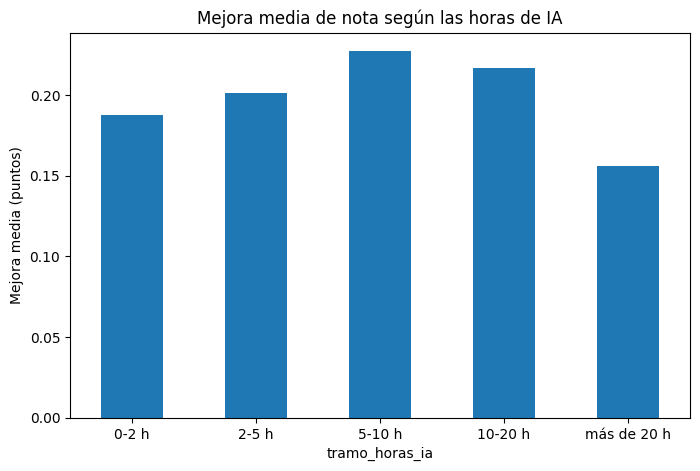

In [ ]:
# Mejora media según las horas semanales de IA
analisis.groupby("tramo_horas_ia", observed=True)["mejora"].mean().plot(kind="bar", figsize=(8, 5))
plt.title("Mejora media de nota según las horas de IA")
plt.ylabel("Mejora media (puntos)")
plt.xticks(rotation=0)
plt.show()

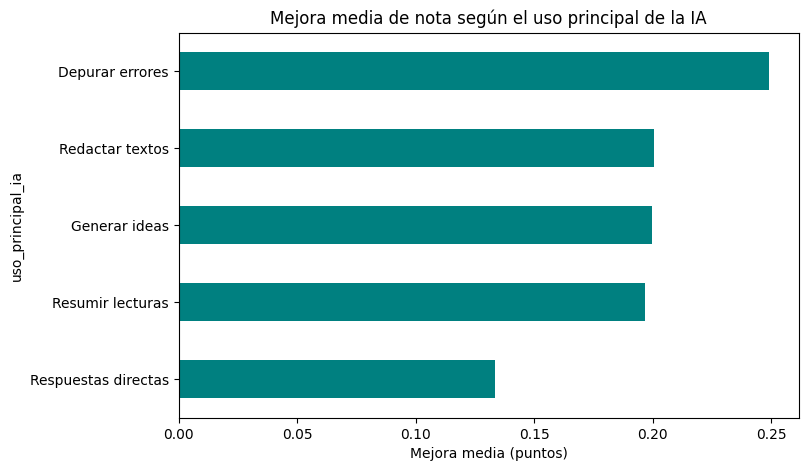

In [ ]:
# Mejora media según el uso principal de la IA
analisis.groupby("uso_principal_ia")["mejora"].mean().sort_values().plot(kind="barh", color="teal", figsize=(8, 5))
plt.title("Mejora media de nota según el uso principal de la IA")
plt.xlabel("Mejora media (puntos)")
plt.show()

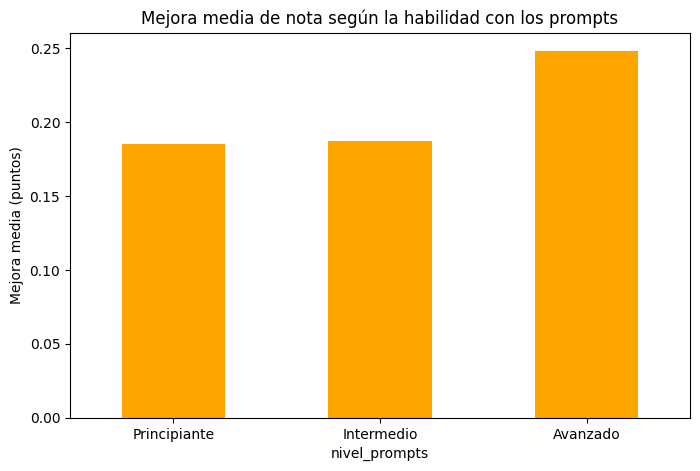

In [ ]:
# Mejora media según la habilidad con los prompts (el orden lo ponemos nosotros)
analisis.groupby("nivel_prompts")["mejora"].mean().loc[ORDENES["nivel_prompts"]].plot(kind="bar", color="orange", figsize=(8, 5))
plt.title("Mejora media de nota según la habilidad con los prompts")
plt.ylabel("Mejora media (puntos)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Tabla con más detalle por tramo de horas de IA
analisis.groupby("tramo_horas_ia", observed=True)[["mejora", "horas_estudio_tradicional", "dependencia_ia", "ansiedad_examenes", "retencion_conocimientos"]].mean().round(2)

,mejora,horas_estudio_tradicional,dependencia_ia,ansiedad_examenes,retencion_conocimientos
tramo_horas_ia,,,,,
0-2 h,0.19,11.89,2.45,3.81,75.60
2-5 h,0.20,11.73,2.78,3.88,76.32
5-10 h,0.23,11.37,3.30,4.07,77.08
10-20 h,0.22,10.63,4.30,4.79,76.59
más de 20 h,0.16,9.30,6.37,5.62,70.25


**Qué vemos (ojo: son medias de grupos, muestran *relación*, no *causa*):**
* **Horas de IA:** el efecto **no es una línea recta**. Quien usa la IA un nivel moderado (5-20 h) mejora más; quien la usa **más de 20 h** semanales mejora bastante menos y estudia menos por su cuenta. Según la tabla, ese grupo también tiene **más dependencia, más ansiedad y menos retención** de conocimientos.
* **Para qué se usa:** *depurar errores* es el uso con mayor mejora; pedir *respuestas directas* es el de menor mejora.
* **Habilidad con los prompts:** el nivel *Avanzado* mejora más que los otros dos.
* Las diferencias son de unas décimas de punto, es decir, **pequeñas comparadas con la nota previa**, pero son claras.
* Por eso, aunque la correlación lineal de `horas_ia` era casi cero, **sí hay información útil** que un modelo que no sea una recta (como un árbol o un bosque) puede aprovechar.


## 4. Exposición del objetivo

**Objetivo del proyecto:** predecir la **nota media final del semestre** de un estudiante (`nota_final`) a partir de sus datos académicos, sus hábitos de estudio y su uso de la IA.

* **Target (lo que predecimos):** `nota_final`.
* **Características (con lo que predecimos):** las otras columnas, **excepto** `id_estudiante`, que solo es un identificador y no aporta información.
* **Tipo de problema:**
  * **Aprendizaje supervisado**, porque conocemos la nota final real de cada estudiante (los datos están etiquetados).
  * **Regresión**, porque la nota es un número y no una categoría. Como usamos muchas columnas, es una **regresión múltiple**.
* **Cómo medimos el rendimiento:**
  * **RMSE** (raíz del error cuadrático medio): el error típico del modelo en puntos de nota. Cuanto más bajo, mejor.
  * **R²**: porcentaje de la variación de las notas que explica el modelo. Cuanto más alto, mejor.
* **Ejemplo:** si un estudiante tiene una nota final real de 3.50 y el modelo predice 3.30, el error absoluto de esa predicción es 0.20.
* **Modelos de referencia:** para saber si el modelo es realmente bueno lo compararemos con dos casos muy simples: (1) predecir siempre la nota media y (2) usar solo la nota previa.


## 5. Preparación de los datos para los algoritmos de Machine Learning

Pasos que vamos a seguir (los mismos que en clase):
1. Feature engineering: probar a crear atributos nuevos.
2. Gestión de nulos.
3. Conversión de categorías a números.
4. Mezcla de los datos.
5. Separación de `X` (características) e `y` (target).
6. Separación en datos de entrenamiento y de prueba.

### 5.1 Feature engineering (combinaciones de atributos)

Vamos a probar a crear tres atributos nuevos con los que ya tenemos, para ver si se relacionan más con la nota final:
1. `horas_totales`: horas de IA + horas de estudio tradicional.
2. `ratio_ia_estudio`: cuántas horas de IA hay por cada hora de estudio tradicional.
3. `horas_por_herramienta`: horas de IA repartidas entre las herramientas que usa.

In [ ]:
estudiantes["horas_totales"] = estudiantes["horas_ia"] + estudiantes["horas_estudio_tradicional"]
estudiantes["ratio_ia_estudio"] = estudiantes["horas_ia"] / estudiantes["horas_estudio_tradicional"]
estudiantes["horas_por_herramienta"] = estudiantes["horas_ia"] / estudiantes["num_herramientas_ia"]

nuevos_atributos = ["horas_totales", "ratio_ia_estudio", "horas_por_herramienta"]
estudiantes[nuevos_atributos].describe().round(2)

,horas_totales,ratio_ia_estudio,horas_por_herramienta
count,50000.00,50000.00,50000.00
mean,19.64,1.37,3.81
std,9.03,3.10,4.79
min,1.01,0.00,0.00
25%,13.41,0.21,0.88
50%,18.26,0.54,2.22
75%,24.28,1.28,4.84
max,64.15,40.00,40.00


Vemos de nuevo las correlaciones con respecto a la nota final.

In [ ]:
corr_matrix_nuevos = estudiantes.drop(columnas_texto + ["id_estudiante"], axis=1).corr()
corr_matrix_nuevos["nota_final"].sort_values(ascending=False)

,nota_final
nota_final,1.000000
nota_previa,0.926781
retencion_conocimientos,0.169616
horas_estudio_tradicional,0.137653
horas_totales,0.061566
num_herramientas_ia,0.025265
suscripcion_pago,0.005528
dependencia_ia,-0.014180
ansiedad_examenes,-0.015909
horas_ia,-0.018600


Los atributos nuevos **no mejoran** lo que ya teníamos: `horas_totales` (0.06), `ratio_ia_estudio` (-0.06) y `horas_por_herramienta` (-0.02) tienen una correlación con la nota final menor que `horas_estudio_tradicional` (0.14) o `retencion_conocimientos` (0.17).

Igual que en clase, **tomamos la decisión de borrar los atributos nuevos** y quedarnos con los originales. Quitamos también `id_estudiante`, porque solo es un identificador y no sirve para predecir.

In [ ]:
estudiantes = estudiantes.drop(nuevos_atributos + ["id_estudiante"], axis=1)
estudiantes.head()

,rama_estudios,curso,nota_previa,horas_ia,uso_principal_ia,nivel_prompts,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,politica_universidad,ansiedad_examenes,nota_final,retencion_conocimientos,riesgo_agotamiento
0,Humanidades,4º curso,2.418,23.31,Redactar textos,Principiante,1,True,8.13,5,Permitida con cita,6,2.393,86.44,Alto
1,Salud,3º curso,3.821,1.12,Generar ideas,Avanzado,5,False,16.65,3,Permitida con cita,9,3.696,69.39,Bajo
2,Empresa,1º curso,3.398,21.26,Resumir lecturas,Principiante,2,False,10.35,5,Prohibida,9,3.499,73.93,Medio
3,Empresa,4º curso,3.789,1.82,Redactar textos,Intermedio,4,False,15.23,2,Permitida con cita,2,4.000,63.58,Medio
4,STEM,2º curso,3.635,9.29,Depurar errores,Avanzado,4,False,12.55,4,Permitida con cita,4,3.798,100.00,Medio


### 5.2 Gestión de nulos

La mayoría de los algoritmos de ML no trabajan bien cuando faltan datos. Comprobamos si hay filas incompletas.

In [ ]:
incomplete_rows = estudiantes[estudiantes.isnull().any(axis=1)]
incomplete_rows

,rama_estudios,curso,nota_previa,horas_ia,uso_principal_ia,nivel_prompts,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,politica_universidad,ansiedad_examenes,nota_final,retencion_conocimientos,riesgo_agotamiento


La tabla sale **vacía**: no hay ningún nulo. Si los hubiera, tendríamos tres opciones: (1) quitar las filas, (2) quitar la columna entera o (3) rellenar con algún valor, por ejemplo la mediana. En nuestro caso **no hace falta hacer nada**.

### 5.3 Conversión de categorías a números

Los algoritmos de ML trabajan mejor con números que con texto. Primero pasamos `suscripcion_pago` (`True`/`False`) a `1`/`0`. Después usamos la codificación **one-hot** (como en clase): una columna de 0 y 1 por cada categoría.

> Nota: `curso`, `nivel_prompts` y `riesgo_agotamiento` sí tienen un orden natural (por ejemplo Principiante < Intermedio < Avanzado), pero usar *one-hot* también funciona bien y es lo que hemos visto en clase.

In [ ]:
estudiantes["suscripcion_pago"] = estudiantes["suscripcion_pago"].astype(int)

estudiantes = pd.get_dummies(estudiantes, columns=columnas_texto, dtype=int)
estudiantes.head()

,nota_previa,horas_ia,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,ansiedad_examenes,nota_final,retencion_conocimientos,rama_estudios_Artes,...,uso_principal_ia_Resumir lecturas,nivel_prompts_Avanzado,nivel_prompts_Intermedio,nivel_prompts_Principiante,politica_universidad_Fomentada,politica_universidad_Permitida con cita,politica_universidad_Prohibida,riesgo_agotamiento_Alto,riesgo_agotamiento_Bajo,riesgo_agotamiento_Medio
0,2.418,23.31,1,1,8.13,5,6,2.393,86.44,0,...,0,0,0,1,0,1,0,1,0,0
1,3.821,1.12,5,0,16.65,3,9,3.696,69.39,0,...,0,1,0,0,0,1,0,0,1,0
2,3.398,21.26,2,0,10.35,5,9,3.499,73.93,0,...,1,0,0,1,0,0,1,0,0,1
3,3.789,1.82,4,0,15.23,2,2,4.000,63.58,0,...,0,0,1,0,0,1,0,0,0,1
4,3.635,9.29,4,0,12.55,4,4,3.798,100.00,0,...,0,1,0,0,0,1,0,0,0,1


In [ ]:
estudiantes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   nota_previa                              50000 non-null  float64
 1   horas_ia                                 50000 non-null  float64
 2   num_herramientas_ia                      50000 non-null  int64  
 3   suscripcion_pago                         50000 non-null  int64  
 4   horas_estudio_tradicional                50000 non-null  float64
 5   dependencia_ia                           50000 non-null  int64  
 6   ansiedad_examenes                        50000 non-null  int64  
 7   nota_final                               50000 non-null  float64
 8   retencion_conocimientos                  50000 non-null  float64
 9   rama_estudios_Artes                      50000 non-null  int64  
 10  rama_estudios_Empresa                    50000

Ahora todas las columnas son numéricas: hemos pasado de 14 columnas de características a 32.

**Sobre el escalado:** el enunciado habla de "escalar" los datos. En este proyecto no hace falta escalar, porque los modelos que vamos a usar (árboles y Random Forest) no se ven afectados por la escala de las columnas, y la regresión lineal tampoco cambia sus predicciones por escalar. Por eso seguimos el mismo procedimiento de clase.

### 5.4 Mezcla de datos

"Barajamos" el dataset para asegurarnos de que los datos no están agrupados por ningún criterio. `sample(frac=1)` devuelve todas las filas en orden aleatorio, y `random_state=42` hace que el resultado sea siempre el mismo.

In [ ]:
estudiantes = estudiantes.sample(frac=1, random_state=42)
estudiantes.head()

,nota_previa,horas_ia,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,ansiedad_examenes,nota_final,retencion_conocimientos,rama_estudios_Artes,...,uso_principal_ia_Resumir lecturas,nivel_prompts_Avanzado,nivel_prompts_Intermedio,nivel_prompts_Principiante,politica_universidad_Fomentada,politica_universidad_Permitida con cita,politica_universidad_Prohibida,riesgo_agotamiento_Alto,riesgo_agotamiento_Bajo,riesgo_agotamiento_Medio
33553,2.208,1.75,1,1,8.22,2,2,2.582,64.42,0,...,0,0,1,0,1,0,0,0,1,0
9427,2.931,3.08,3,1,11.68,5,8,3.452,82.34,1,...,0,0,0,1,1,0,0,0,1,0
199,2.874,14.28,3,0,13.68,6,5,3.035,87.08,1,...,0,1,0,0,0,0,1,1,0,0
12447,2.517,7.42,1,1,1.00,1,1,2.754,78.94,0,...,0,0,0,1,0,1,0,1,0,0
39489,2.927,3.12,3,0,5.59,3,4,3.084,63.73,0,...,0,0,1,0,1,0,0,0,1,0


### 5.5 Separación de las características (`X`) y el target (`y`)

In [ ]:
y = estudiantes["nota_final"]
y

,nota_final
33553,2.582
9427,3.452
199,3.035
12447,2.754
39489,3.084
...,...
11284,3.820
44732,3.942
38158,4.000
860,2.898


In [ ]:
X = estudiantes.drop("nota_final", axis=1)
X

,nota_previa,horas_ia,num_herramientas_ia,suscripcion_pago,horas_estudio_tradicional,dependencia_ia,ansiedad_examenes,retencion_conocimientos,rama_estudios_Artes,rama_estudios_Empresa,...,uso_principal_ia_Resumir lecturas,nivel_prompts_Avanzado,nivel_prompts_Intermedio,nivel_prompts_Principiante,politica_universidad_Fomentada,politica_universidad_Permitida con cita,politica_universidad_Prohibida,riesgo_agotamiento_Alto,riesgo_agotamiento_Bajo,riesgo_agotamiento_Medio
33553,2.208,1.75,1,1,8.22,2,2,64.42,0,0,...,0,0,1,0,1,0,0,0,1,0
9427,2.931,3.08,3,1,11.68,5,8,82.34,1,0,...,0,0,0,1,1,0,0,0,1,0
199,2.874,14.28,3,0,13.68,6,5,87.08,1,0,...,0,1,0,0,0,0,1,1,0,0
12447,2.517,7.42,1,1,1.00,1,1,78.94,0,0,...,0,0,0,1,0,1,0,1,0,0
39489,2.927,3.12,3,0,5.59,3,4,63.73,0,1,...,0,0,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,3.589,2.19,1,1,10.95,4,4,63.34,0,0,...,0,0,0,1,0,0,1,0,1,0
44732,3.793,2.36,2,0,18.42,3,9,97.35,0,0,...,0,0,0,1,0,1,0,0,1,0
38158,3.804,8.22,1,1,13.26,4,5,86.00,0,0,...,0,0,0,1,0,1,0,1,0,0
860,2.899,16.62,1,0,6.94,7,9,84.80,1,0,...,0,0,0,1,1,0,0,0,0,1


### 5.6 Datos de entrenamiento y de prueba

Separamos el dataset en dos partes:
* Datos de entrenamiento (*training set*): 80 % (40.000 estudiantes).
* Datos de prueba (*test set*): 20 % (10.000 estudiantes). **No los tocamos hasta el final.**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(X_train.shape, X_test.shape)

(40000, 32) (10000, 32)


Si todo es correcto, la distribución de los datos de entrenamiento y de test debe ser parecida. Lo comprobamos con un par de atributos.

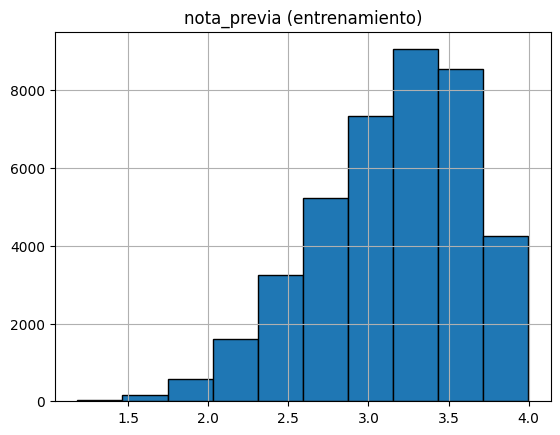

In [ ]:
X_train["nota_previa"].hist(edgecolor="black")
plt.title("nota_previa (entrenamiento)")
plt.show()

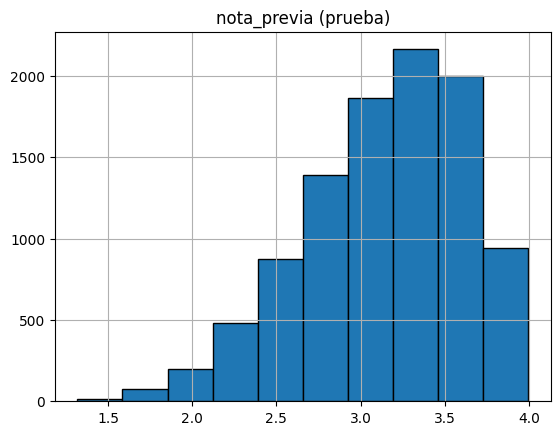

In [ ]:
X_test["nota_previa"].hist(edgecolor="black")
plt.title("nota_previa (prueba)")
plt.show()

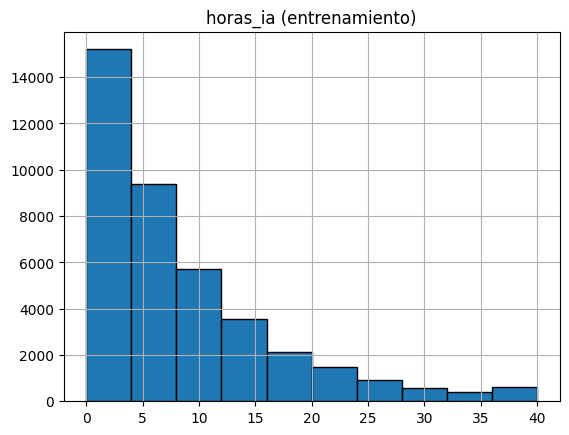

In [ ]:
X_train["horas_ia"].hist(edgecolor="black")
plt.title("horas_ia (entrenamiento)")
plt.show()

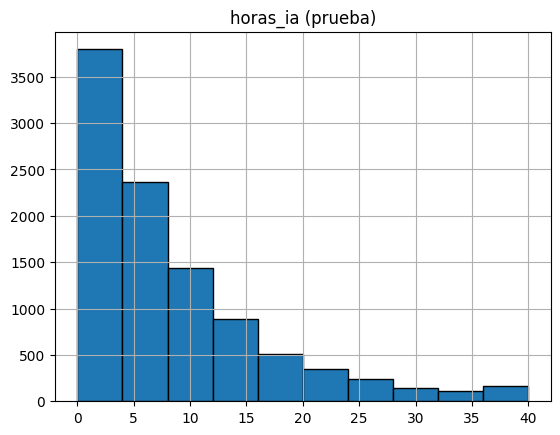

In [ ]:
X_test["horas_ia"].hist(edgecolor="black")
plt.title("horas_ia (prueba)")
plt.show()

**Qué vemos:** las formas son casi iguales, así que el reparto es razonable y las dos partes representan bien al conjunto.


## 6. Entrenamiento del modelo y comprobación del rendimiento

Es un caso típico de regresión. Probaremos los tres modelos vistos en clase: **regresión lineal**, **árbol de decisión** y **Random Forest**. Después ajustaremos los hiperparámetros del Random Forest y, para terminar, evaluaremos el mejor con los datos de prueba.

### 6.1 Regresión lineal

In [ ]:
from sklearn.linear_model import LinearRegression

# Instancia el modelo (se crea un objeto a partir de la clase que implementa el algoritmo)
model_lineal = LinearRegression()

# Entrena el modelo
model_lineal.fit(X_train, y_train)

# Predicciones (en principio sobre los datos de entrenamiento)
y_pred_train = model_lineal.predict(X_train)
y_train_list = y_train.to_list()

print("Nota real   Nota estimada   Error absoluto  (entrenamiento)")

for i in range(20):
  r = y_train_list[i]   # nota real
  e = y_pred_train[i]   # nota estimada
  e_abs = abs(r - e)    # valor absoluto
  print(f"{r:9.3f}   {e:13.3f}   {e_abs:15.3f}")

Nota real   Nota estimada   Error absoluto  (entrenamiento)
    3.787           3.627             0.160
    3.816           3.691             0.125
    4.000           4.066             0.066
    4.000           4.047             0.047
    2.245           2.332             0.087
    2.917           2.719             0.198
    3.521           3.755             0.234
    3.444           3.541             0.097
    4.000           4.139             0.139
    3.753           3.365             0.388
    2.807           2.799             0.008
    3.189           3.037             0.152
    4.000           4.022             0.022
    2.856           2.833             0.023
    4.000           4.007             0.007
    2.749           2.563             0.186
    3.899           3.753             0.146
    3.084           3.322             0.238
    3.814           3.307             0.507
    3.445           3.442             0.003


Calculamos el **RMSE** y el **R²** sobre los mismos datos que hemos usado para entrenar el modelo.

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

print(f"RMSE (entrenamiento): {rmse_train:.4f}")
print(f"R^2 (entrenamiento): {r2_train:.4f}")

RMSE (entrenamiento): 0.1595
R^2 (entrenamiento): 0.8967


### 6.2 Validación cruzada (*cross-validation*)

Evaluar el modelo con los mismos datos con los que se ha entrenado no es fiable. La validación cruzada permite medir mejor su capacidad de acertar con datos nuevos, **sin tocar el conjunto de prueba**.

Funciona así:
1. Se divide el entrenamiento en **K partes** iguales.
2. Se entrena con K-1 partes y se mide el error en la parte que queda.
3. Se repite K veces, cambiando cada vez la parte de validación.
4. Se hace la media de los resultados.

Aquí usamos **K = 3**: se entrena con 2/3 de los datos y se valida con el 1/3 restante, tres veces.

In [ ]:
from sklearn.model_selection import cross_validate

def evaluar_cv(modelo, nombre, datos=X_train):
    # Validación cruzada con 3 partes. Calculamos dos medidas: RMSE y R².
    puntuaciones = cross_validate(
        modelo, datos, y_train, cv=3,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )

    # Scikit-learn devuelve el RMSE en negativo (porque considera que más grande es mejor).
    # Cambiamos el signo para verlo como un error normal: cuanto más bajo, mejor.
    rmse = -puntuaciones["test_rmse"].mean()
    r2 = puntuaciones["test_r2"].mean()

    print(f"{nombre}: RMSE medio (validación cruzada) = {rmse:.4f} | R² medio = {r2:.4f}")

    # Devolvemos los resultados en un diccionario para poder comparar modelos
    return {"Modelo": nombre, "RMSE CV": rmse, "R² CV": r2}

resultados_cv = []
resultados_cv.append(evaluar_cv(model_lineal, "Regresión lineal"))

Regresión lineal: RMSE medio (validación cruzada) = 0.1597 | R² medio = 0.8965


### 6.3 Árbol de decisión

In [ ]:
from sklearn.tree import DecisionTreeRegressor

modelo_arbol = DecisionTreeRegressor(random_state=42)
modelo_arbol.fit(X_train, y_train)

y_pred_train = modelo_arbol.predict(X_train)
rmse_train_arbol = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"RMSE (entrenamiento) del árbol: {rmse_train_arbol:.4f}")

RMSE (entrenamiento) del árbol: 0.0000


In [ ]:
# Aplicamos la validación cruzada al árbol de decisión
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

Árbol de decisión: RMSE medio (validación cruzada) = 0.2238 | R² medio = 0.7968


**Qué vemos (sobreajuste):** en entrenamiento el árbol tiene un error de **0.00** (acierta todo: se ha aprendido los datos de memoria), pero en validación cruzada el error sube a **0.223**. Esto se llama **sobreajuste** (*overfitting*): el modelo memoriza en vez de aprender. Por eso nunca hay que fiarse del error medido con los datos de entrenamiento.

### 6.4 Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# random_state=42 hace que el resultado sea siempre el mismo; n_jobs=-1 usa todos los procesadores
modelo_bosque = RandomForestRegressor(random_state=42, n_jobs=-1)
modelo_bosque.fit(X_train, y_train)

y_pred_train = modelo_bosque.predict(X_train)
rmse_train_bosque = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"RMSE (entrenamiento) del Random Forest: {rmse_train_bosque:.4f}")

RMSE (entrenamiento) del Random Forest: 0.0579


In [ ]:
# Aplicamos la validación cruzada al Random Forest
resultados_cv.append(evaluar_cv(modelo_bosque, "Random Forest"))

Random Forest: RMSE medio (validación cruzada) = 0.1559 | R² medio = 0.9013


In [ ]:
# Comparativa de modelos
pd.DataFrame(resultados_cv).round(4)

,Modelo,RMSE CV,R² CV
0,Regresión lineal,0.1597,0.8965
1,Árbol de decisión,0.2238,0.7968
2,Random Forest,0.1559,0.9013


**Qué vemos:** el **Random Forest** es el mejor hasta ahora: su RMSE en validación cruzada (0.156) es el más bajo y su R² es el más cercano a 1. Un Random Forest es un conjunto de muchos árboles que votan, y por eso sobreajusta mucho menos que un árbol solo. Aun así, en entrenamiento el error es mucho menor (0.058) que en validación: todavía memoriza algo. Vamos a intentar mejorarlo.

### 6.5 Ajuste de hiperparámetros

Un **parámetro** es un valor que el algoritmo aprende de los datos. Un **hiperparámetro** lo fijamos nosotros *antes* de entrenar y controla cómo aprende el modelo. Ajustaremos estos del Random Forest:

* `n_estimators`: número de árboles del bosque.
* `max_depth`: profundidad máxima de cada árbol (limitarla evita que memorice).
* `min_samples_leaf`: mínimo de estudiantes en cada hoja del árbol (también evita memorizar).
* `max_features`: fracción de columnas que mira cada árbol al decidir. Con `0.5` cada árbol mira la mitad, así los árboles se parecen menos entre sí y el bosque vota mejor.

**GridSearchCV** prueba todas las combinaciones de una rejilla y se queda con la que da menor RMSE en validación cruzada. Para que no tarde demasiado, buscamos sobre una muestra aleatoria de 5.000 estudiantes **del conjunto de entrenamiento** (el de prueba no se toca). Después comprobamos el modelo ajustado con validación cruzada sobre **todo** el entrenamiento.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Muestra de 5.000 estudiantes sacada solo del entrenamiento
X_busqueda = X_train.sample(n=5000, random_state=42)
y_busqueda = y_train.loc[X_busqueda.index]

rejilla = {
    "n_estimators": [50, 100],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [3, 5, 10],
    "max_features": [0.5, 1.0]
}
busqueda_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rejilla,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
busqueda_grid.fit(X_busqueda, y_busqueda)

print("Mejores hiperparámetros:", busqueda_grid.best_params_)
print(f"RMSE CV durante la búsqueda: {-busqueda_grid.best_score_:.4f}")

# Comparamos el modelo ajustado en las MISMAS condiciones que los anteriores
modelo_bosque_ajustado = RandomForestRegressor(
    **busqueda_grid.best_params_, random_state=42, n_jobs=-1
)
resultados_cv.append(evaluar_cv(modelo_bosque_ajustado, "Random Forest ajustado"))
modelo_bosque_ajustado.fit(X_train, y_train)

Mejores hiperparámetros: {'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 100}
RMSE CV durante la búsqueda: 0.1623
Random Forest ajustado: RMSE medio (validación cruzada) = 0.1529 | R² medio = 0.9052


RandomForestRegressor(max_depth=12, max_features=0.5, min_samples_leaf=3,
                      n_jobs=-1, random_state=42)

### 6.6 Comparación final de modelos

In [ ]:
# Comparamos los modelos con la misma validación cruzada
tabla_resultados = pd.DataFrame(resultados_cv).sort_values("RMSE CV").reset_index(drop=True)
print("Comparación mediante validación cruzada (menor RMSE es mejor):")
display(tabla_resultados.round(4))

# Elegimos el mejor modelo según el RMSE de validación cruzada, sin usar el test.
modelos = {
    "Regresión lineal": model_lineal,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_bosque,
    "Random Forest ajustado": modelo_bosque_ajustado
}
nombre_final = tabla_resultados.loc[0, "Modelo"]   # el primero de la tabla ordenada
modelo_final = modelos[nombre_final]
print("Modelo seleccionado:", nombre_final)

Comparación mediante validación cruzada (menor RMSE es mejor):


,Modelo,RMSE CV,R² CV
0,Random Forest ajustado,0.1529,0.9052
1,Random Forest,0.1559,0.9013
2,Regresión lineal,0.1597,0.8965
3,Árbol de decisión,0.2238,0.7968


Modelo seleccionado: Random Forest ajustado


**Qué vemos:** ajustar los hiperparámetros mejora el Random Forest: baja el RMSE de 0.1560 a 0.1529. Los hiperparámetros elegidos son: `max_depth` = 12, `max_features` = 0.5, `min_samples_leaf` = 3, `n_estimators` = 100. El mejor modelo es el **Random Forest ajustado**.

### 6.7 Prueba con los datos de test

Ahora usamos los datos de prueba, **una sola vez**, con el modelo elegido.

In [ ]:
y_pred_test = modelo_final.predict(X_test)
y_test_list = y_test.to_list()

print("Nota real   Nota estimada   Error absoluto  (test)")

for i in range(20):
  r = y_test_list[i]
  e = y_pred_test[i]
  e_abs = abs(r - e)
  print(f"{r:9.3f}   {e:13.3f}   {e_abs:15.3f}")

Nota real   Nota estimada   Error absoluto  (test)
    2.958           2.944             0.014
    3.622           3.611             0.011
    3.763           3.688             0.075
    3.525           3.706             0.181
    3.637           3.402             0.235
    2.781           2.843             0.062
    3.218           3.196             0.022
    3.026           3.458             0.432
    3.262           3.072             0.190
    3.889           3.900             0.011
    3.854           3.967             0.113
    2.961           2.898             0.063
    2.566           2.575             0.009
    3.702           3.598             0.104
    3.155           3.076             0.079
    3.144           3.196             0.052
    3.895           3.903             0.008
    3.330           3.371             0.041
    3.805           3.706             0.099
    4.000           3.969             0.031


In [ ]:
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"RMSE en test: {rmse_test:.4f}")
print(f"R² en test:   {r2_test:.4f}  (explica el {r2_test*100:.1f} % de la variación de las notas)")

# Los modelos de referencia, también sobre los datos de test
rmse_media_test = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
modelo_ref = LinearRegression().fit(X_train[["nota_previa"]], y_train)
rmse_base_test = np.sqrt(mean_squared_error(y_test, modelo_ref.predict(X_test[["nota_previa"]])))

print(f"\nPara comparar -> predecir siempre la media: RMSE = {rmse_media_test:.4f}")
print(f"                 usar solo la nota previa:   RMSE = {rmse_base_test:.4f}")

RMSE en test: 0.1504
R² en test:   0.9068  (explica el 90.7 % de la variación de las notas)

Para comparar -> predecir siempre la media: RMSE = 0.4926
                 usar solo la nota previa:   RMSE = 0.1849


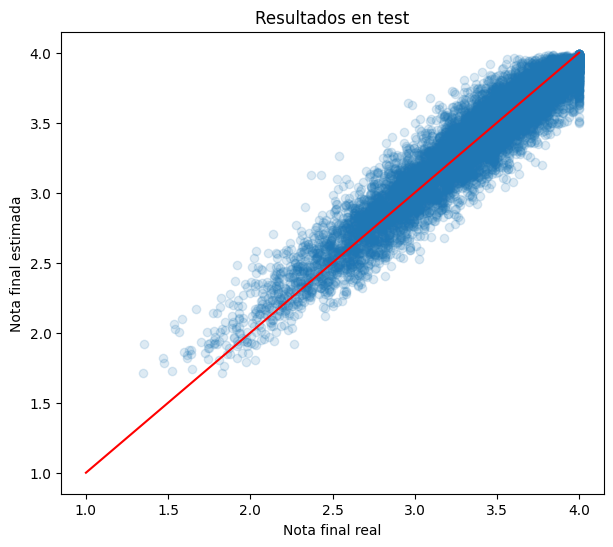

In [ ]:
# Nota real frente a nota estimada: si el modelo fuera perfecto, todos los puntos estarían sobre la línea roja
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_test, alpha=0.15)
plt.plot([1, 4], [1, 4], color="red")
plt.xlabel("Nota final real")
plt.ylabel("Nota final estimada")
plt.title("Resultados en test")
plt.show()

**Qué vemos:** el RMSE en test (0.151) es muy parecido al de validación cruzada (0.153), así que el modelo **generaliza bien**. Mejora a los modelos de referencia (0.185 usando solo la nota previa y 0.493 con la media). En la gráfica los puntos se agrupan alrededor de la diagonal. Arriba a la derecha se ve que, como la nota real nunca pasa de 4.0, los estudiantes con un 4.0 reciben predicciones muy repartidas.

### 6.8 ¿Qué columnas usa más el modelo?

La **importancia de las características** es orientativa: nos dice qué columnas usa más el bosque, pero **no** implica que una columna cause la otra.

Las 10 características más importantes:


,Importancia
nota_previa,0.917
horas_estudio_tradicional,0.027
retencion_conocimientos,0.014
horas_ia,0.009
curso_1º curso,0.005
uso_principal_ia_Depurar errores,0.004
nivel_prompts_Avanzado,0.003
uso_principal_ia_Respuestas directas,0.003
dependencia_ia,0.002
ansiedad_examenes,0.002


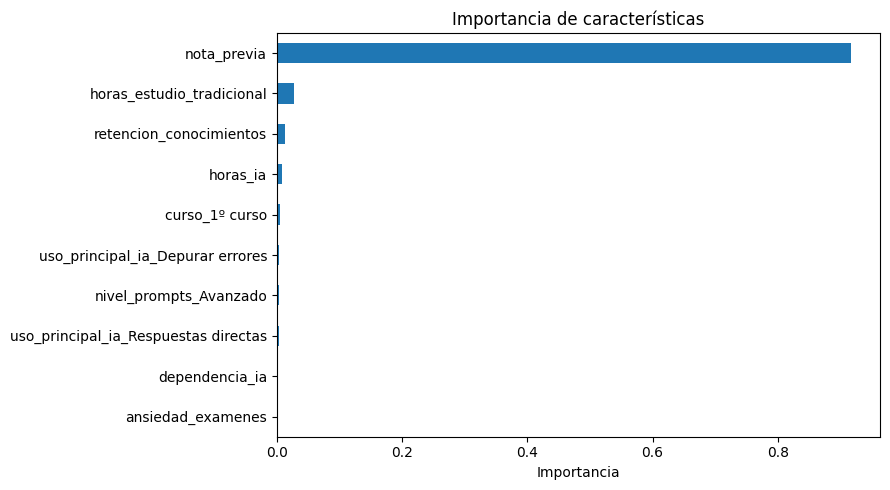

In [ ]:
# Interpretación básica del bosque aleatorio (si ha sido el elegido)
if hasattr(modelo_final, "feature_importances_"):
    importancias = pd.Series(
        modelo_final.feature_importances_, index=X_train.columns
    ).sort_values(ascending=False)
    print("Las 10 características más importantes:")
    display(importancias.head(10).round(3).to_frame("Importancia"))
    importancias.head(10).sort_values().plot.barh(figsize=(9, 5), title="Importancia de características")
    plt.xlabel("Importancia")
    plt.tight_layout()
    plt.show()
else:
    print("El modelo elegido no proporciona feature_importances_.")

**Qué vemos:** `nota_previa` es la característica más importante con diferencia (92% de la importancia). Después aparecen `horas_estudio_tradicional`, `retencion_conocimientos`, `horas_ia`, `curso_1º curso`. Recuerda que las categorías (como `uso_principal_ia`) se han convertido en varias columnas de 0/1, así que su importancia aparece repartida entre ellas.

### 6.9 Predicción de nuevos estudiantes

Una vez elegido y evaluado el modelo, lo usamos con tres **estudiantes ficticios**. Los estudiantes A y B tienen la misma nota previa (3.2) pero hábitos muy distintos. Como son datos nuevos, no conocemos su nota real y no podemos calcular el error.

In [ ]:
# Tres estudiantes ficticios con las características originales
datos_nuevos = pd.DataFrame([
    {   # A: uso moderado de la IA, para depurar errores, buen nivel de prompts y estudio por su cuenta
        "rama_estudios": "STEM", "curso": "3º curso", "nota_previa": 3.2, "horas_ia": 8,
        "uso_principal_ia": "Depurar errores", "nivel_prompts": "Avanzado", "num_herramientas_ia": 3,
        "suscripcion_pago": 0, "horas_estudio_tradicional": 12, "dependencia_ia": 3,
        "politica_universidad": "Permitida con cita", "ansiedad_examenes": 4,
        "retencion_conocimientos": 78, "riesgo_agotamiento": "Medio"
    },
    {   # B: mucho uso de la IA, para pedir respuestas directas, poco estudio por su cuenta
        "rama_estudios": "STEM", "curso": "3º curso", "nota_previa": 3.2, "horas_ia": 30,
        "uso_principal_ia": "Respuestas directas", "nivel_prompts": "Principiante", "num_herramientas_ia": 3,
        "suscripcion_pago": 0, "horas_estudio_tradicional": 6, "dependencia_ia": 8,
        "politica_universidad": "Permitida con cita", "ansiedad_examenes": 7,
        "retencion_conocimientos": 60, "riesgo_agotamiento": "Alto"
    },
    {   # C: casi no usa la IA, nota previa más baja, 1º curso
        "rama_estudios": "Humanidades", "curso": "1º curso", "nota_previa": 2.5, "horas_ia": 2,
        "uso_principal_ia": "Redactar textos", "nivel_prompts": "Intermedio", "num_herramientas_ia": 2,
        "suscripcion_pago": 0, "horas_estudio_tradicional": 10, "dependencia_ia": 2,
        "politica_universidad": "Permitida con cita", "ansiedad_examenes": 5,
        "retencion_conocimientos": 72, "riesgo_agotamiento": "Bajo"
    }
], index=["Estudiante A", "Estudiante B", "Estudiante C"])

# Convertimos las categorías igual que con los datos de entrenamiento
X_nuevos = pd.get_dummies(datos_nuevos, columns=columnas_texto, dtype=int)

# Aseguramos que las columnas coincidan exactamente con las de entrenamiento
# (las categorías que no aparecen se rellenan con ceros)
X_nuevos = X_nuevos.reindex(columns=X_train.columns, fill_value=0)

notas_estimadas = modelo_final.predict(X_nuevos)
resultados_nuevos = pd.DataFrame({"Nota previa": datos_nuevos["nota_previa"],
                                  "Nota final estimada": notas_estimadas}, index=datos_nuevos.index)
display(resultados_nuevos.round(2))

,Nota previa,Nota final estimada
Estudiante A,3.2,3.58
Estudiante B,3.2,3.06
Estudiante C,2.5,2.59


**Qué vemos:** el estudiante A y el B parten de la misma nota previa (3.20), pero el modelo estima **3.58** para A (uso moderado de la IA para depurar, buen nivel de prompts y más estudio propio) y **3.05** para B (mucho uso de la IA para pedir respuestas directas y poco estudio propio). Para C, que parte de 2.5, estima 2.59. Recuerda que el modelo solo refleja las relaciones que hay en estos datos (probablemente simulados): no demuestra que cambiar los hábitos produzca esa diferencia de nota.


## 7. Conclusiones

Hemos recorrido todas las etapas de un proyecto de Machine Learning: obtención y descripción de los datos, exploración, preparación, entrenamiento, validación cruzada, ajuste de hiperparámetros, prueba final y predicción de nuevos casos.

**Resultado del modelo**
* El mejor modelo es el **Random Forest ajustado**. En los datos de prueba tiene un **RMSE de 0.151** (se equivoca de forma típica unos 0.15 puntos en una escala de 0 a 4) y un **R² de 0.907**.
* **Lo importante es la comparación:** predecir siempre la media daría un error de 0.493 y usar solo la nota previa de 0.185. Nuestro modelo reduce el error de este segundo caso en un **19 %**. Es decir, la nota previa hace casi todo el trabajo, pero los hábitos de estudio y de uso de la IA aportan una mejora real.
* El error en validación cruzada (0.153) y en test (0.151) es muy parecido, señal de que el modelo **generaliza bien**.

**Sobre los modelos**
* El **árbol de decisión** sobreajusta: tiene error 0.00 en entrenamiento y 0.223 en validación cruzada.
* El **Random Forest** lo soluciona (0.156), y **ajustar los hiperparámetros** lo mejora un poco más (0.153). La **regresión lineal** funciona bastante bien (0.160) porque la relación principal (nota previa → nota final) es lineal, pero el bosque capta además relaciones que no son una recta, como las de las horas de IA.

**Sobre el impacto de la IA en los estudiantes** *(son relaciones entre variables, no pruebas de causa y efecto)*
* **Ni mucha ni ninguna:** el uso moderado de IA (5-20 h semanales) se relaciona con la mayor mejora de nota; el uso excesivo (más de 20 h) se relaciona con una mejora menor y con menos horas de estudio propio.
* **Importa para qué se usa:** depurar errores se asocia con mayor mejora que pedir respuestas directas.
* **Importa cómo se usa:** los estudiantes con nivel avanzado de *prompts* mejoran más.
* **El estudio tradicional sigue siendo clave:** `horas_estudio_tradicional` está entre las características más importantes del modelo.
* **Uso excesivo y malestar:** quienes usan la IA más de 20 h semanales tienen de media más dependencia percibida, más ansiedad en los exámenes y menor retención de conocimientos. Es una relación, no sabemos si la IA es la causa.

**Limitaciones**
* Los datos parecen **simulados**, así que no podemos asegurar que pasaría lo mismo con estudiantes reales.
* La `nota_final` tiene un **tope de 4.0** (un 9.6 % de estudiantes lo alcanza), lo que dificulta predecir bien las notas más altas.
* Que dos cosas vayan unidas no significa que una cause la otra. Por ejemplo, puede ser que los estudiantes con más ansiedad usen más la IA, y no al revés.
* Algunas columnas (retención de conocimientos, ansiedad en exámenes) probablemente se miden durante o al final del semestre, así que solo servirían para predecir **después** de medirlas.

**Posibles mejoras**
* Probar con datos reales de otra universidad.
* Probar otros algoritmos más avanzados que los vistos en clase.
* Predecir directamente la **mejora** (`nota_final - nota_previa`), un problema más difícil pero que responde más directamente a la pregunta "¿qué hábitos ayudan a subir la nota?".